# Task 1 — Prove why we visualize (`datasaurus.csv`)

**Data:** 1,846 rows × 3 columns (`dataset`, `x`, `y`): 13 datasets of 142 points each.
**Plan:** (1) summary-statistics table, (2) what the table alone says, (3) grid of 13 scatter plots, (4) what I actually found, (5) does more data make the statistics more trustworthy?

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


candidates = [Path(p) for p in ["datasaurus.csv", "data/datasaurus.csv", "../data/datasaurus.csv", "../datasaurus.csv"]]
path = next((p for p in candidates if p.exists()), None) or next(Path("..").rglob("datasaurus.csv"))
df = pd.read_csv(path)


assert df.shape == (1846, 3), df.shape
assert df["dataset"].nunique() == 13
assert (df.groupby("dataset").size() == 142).all()
print(f"Loaded {path}: {df.shape[0]:,} rows, {df['dataset'].nunique()} datasets x {df.groupby('dataset').size().iloc[0]} points")
print("Missing values:", int(df.isna().sum().sum()))
df.head()

Loaded datasaurus.csv: 1,846 rows, 13 datasets x 142 points
Missing values: 0


,dataset,x,y
0,dino,55.3846,97.1795
1,dino,51.5385,96.0256
2,dino,46.1538,94.4872
3,dino,42.8205,91.4103
4,dino,40.7692,88.3333


## Step 1 — Summary statistics for each of the 13 datasets
Mean and standard deviation of `x` and `y` (sample SD, `ddof=1`) and the Pearson correlation between them. The last row shows how far apart the 13 datasets are on each statistic (max − min).

In [2]:
g = df.groupby("dataset")
stats = g.agg(mean_x=("x", "mean"), mean_y=("y", "mean"), sd_x=("x", "std"), sd_y=("y", "std"))
stats["corr_xy"] = g.apply(lambda d: d["x"].corr(d["y"]), include_groups=False)

table = stats.round(2)
spread = (stats.max() - stats.min()).round(3)
spread.name = "range across 13 (max - min)"
table = pd.concat([table, spread.to_frame().T])
table

,mean_x,mean_y,sd_x,sd_y,corr_xy
away,54.27,47.83,16.77,26.94,-0.060
bullseye,54.27,47.83,16.77,26.94,-0.070
circle,54.27,47.84,16.76,26.93,-0.070
dino,54.26,47.83,16.77,26.94,-0.060
dots,54.26,47.84,16.77,26.93,-0.060
h_lines,54.26,47.83,16.77,26.94,-0.060
high_lines,54.27,47.84,16.77,26.94,-0.070
slant_down,54.27,47.84,16.77,26.94,-0.070
slant_up,54.27,47.83,16.77,26.94,-0.070
star,54.27,47.84,16.77,26.93,-0.060


## Step 2 — What I would conclude if the table were all I had
Reading only the table, I would say that all 13 datasets are essentially **the same dataset**. Every one has a mean of about 54.3 for `x` and 47.8 for `y`, a standard deviation of about 16.8 for `x` and 26.9 for `y`, and a weak **negative** correlation of about −0.06. The "range" row shows the 13 datasets differ by about 0.01 on every statistic, which is rounding noise.

So I would conclude: *`x` and `y` are basically unrelated (r ≈ −0.06), `y` is more spread out than `x`, and the data is a shapeless cloud centred on (54, 48), probably the same process measured 13 times.* The table gives me no reason to think any dataset is different from the others.

## Step 3 — All 13 datasets as a grid of scatter plots

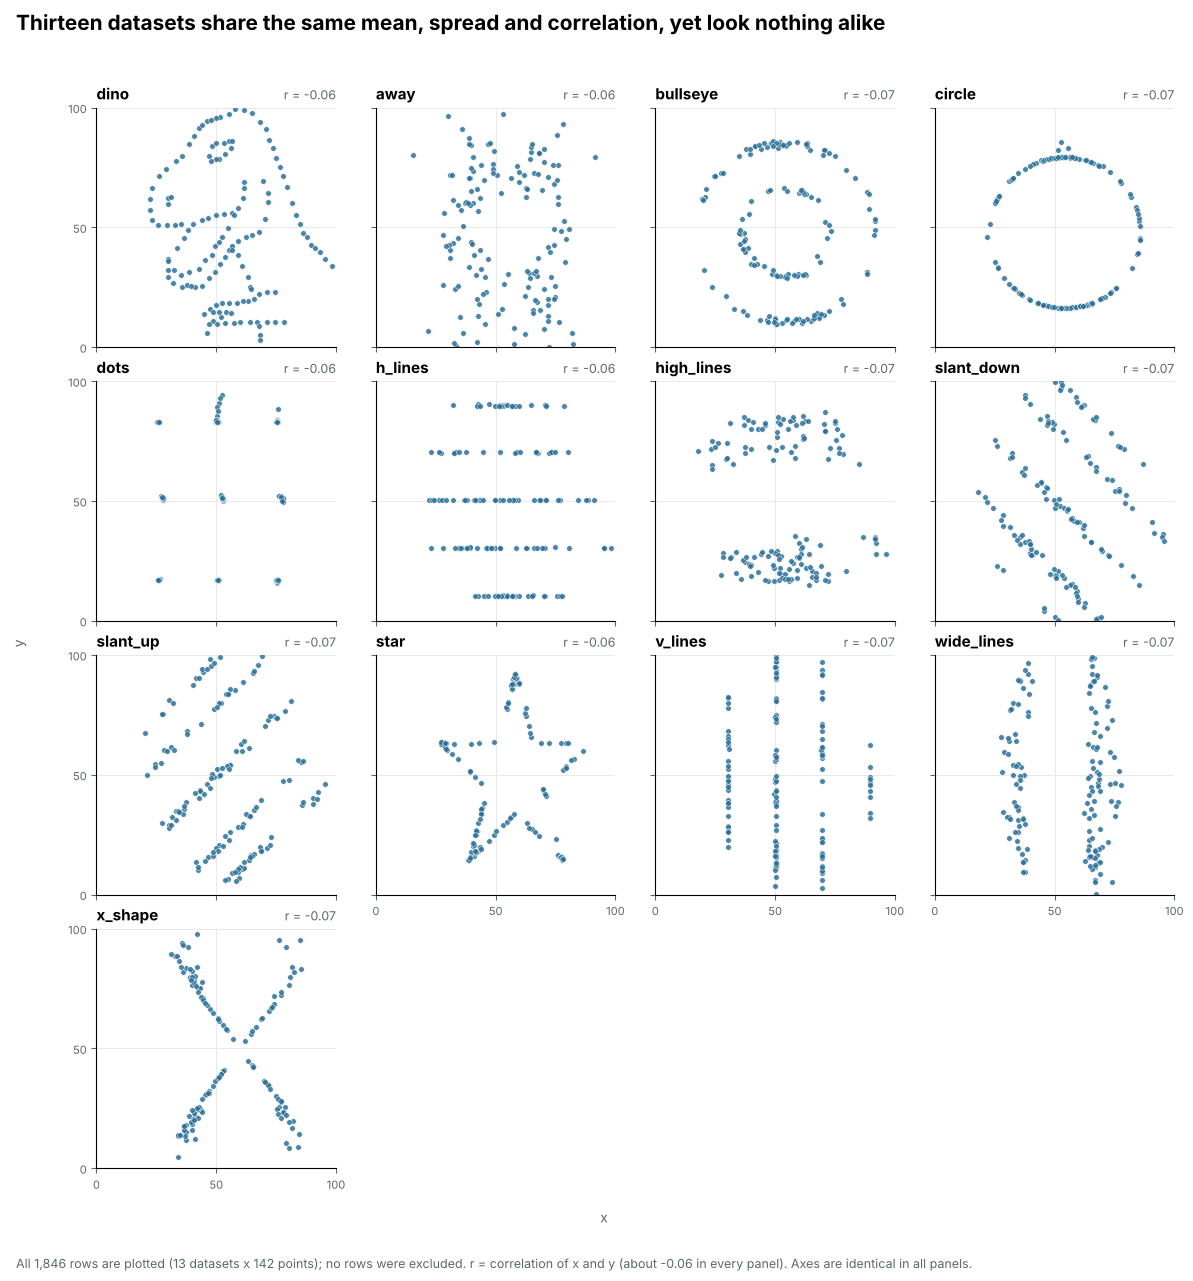

In [ ]:
COLOR = "#2A6F97"   
MUTED = "#5B6770"

order = ["dino"] + sorted(d for d in df["dataset"].unique() if d != "dino")

fig, axes = plt.subplots(4, 4, figsize=(12, 12.8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, order):
    d = df[df["dataset"] == name]
    ax.scatter(d["x"], d["y"], s=16, color=COLOR, alpha=0.85, edgecolor="white", linewidth=0.4)
    ax.set_title(name, loc="left", fontsize=11, fontweight="bold")
    ax.set_title(f"r = {d['x'].corr(d['y']):.2f}", loc="right", fontsize=9, color=MUTED)   # beside the title, so it never covers points
    ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.set_aspect("equal")
    ax.set_xticks([0, 50, 100]); ax.set_yticks([0, 50, 100])
    ax.grid(color="#E3E6E8", linewidth=0.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(labelsize=8, colors=MUTED)

# 13 panels in a 4x4 grid: hide the 3 unused cells, keep x tick labels on the last used panel in each column
for ax in axes.flat[len(order):]:
    ax.set_visible(False)
for ax in axes.flat[9:13]:
    ax.tick_params(labelbottom=True)

fig.suptitle("Thirteen datasets share the same mean, spread and correlation, yet look nothing alike",
             x=0.01, ha="left", fontsize=15, fontweight="bold", y=0.995)
fig.supxlabel("x", fontsize=10, color=MUTED, y=0.045)
fig.supylabel("y", fontsize=10, color=MUTED, x=0.005)
fig.text(0.01, 0.012,
         "All 1,846 rows are plotted (13 datasets x 142 points); no rows were excluded. "
         "r = correlation of x and y (about -0.06 in every panel). Axes are identical in all panels.",
         fontsize=9, color=MUTED, ha="left")
fig.tight_layout(rect=(0.01, 0.04, 1, 0.975))
plt.show()

**Why a grid of scatter plots?**
- **Scatter plot, because the question is about the relationship between two numeric variables.** Each dataset is 142 (x, y) pairs, and a scatter plot shows every pair, so the *shape* of the joint distribution is visible. A line chart would imply `x` is an ordered sequence, and a bar chart would collapse the 142 points back into one summary number per dataset, which is exactly what hid the differences in the table. 142 points per panel is small enough that overplotting is not a problem, so no binning or transparency tricks are needed.
- **Small multiples (one panel per dataset), because overlaying 13 point clouds on one plot would be unreadable.** Separate panels with **identical x and y axes** let the eye compare shapes directly, and the shared 0–100 scale means no panel can look different just because of a different zoom.
- **One colour on purpose.** The panel title already says which dataset it is, so a colour-per-dataset legend would add nothing. I removed colour as an encoding rather than decorate with it. There is one y-axis per panel and no dual axes. Bars are not used, so the zero-baseline rule does not apply, but I kept the axes starting at 0 anyway so the shapes are not exaggerated.
- **Selective labelling.** The only labels are the dataset name and the correlation `r` per panel. `r` is printed on purpose, because it shows that the number the table relied on is nearly the same (−0.06 to −0.07) in panels that look completely different.
- **Title states the finding**, and the footnote says that no rows were excluded.

## Step 4 — What I actually found
Once the data is plotted, the "same dataset" conclusion from the table is completely wrong. The 13 datasets have very different structure: one is a **dinosaur**, others are a **star**, a **circle**, a **bullseye** (a ring with a core), an **X** made of two crossing lines, parallel **horizontal**, **vertical** and **sloped lines**, and a grid of tight **clusters** (`dots`). Only `away` looks like the shapeless cloud I imagined from the table. The summary statistics agree to within about 0.01, so they could not tell me any of this.

The statistics also describe the wrong thing for most of the panels. A correlation of −0.06 says "no *linear* relationship", but in `circle`, `bullseye` and `x_shape` there is clearly a strong *pattern*, just not a straight-line one. In `h_lines` and `v_lines` the data sits on a handful of exact values, which a mean and standard deviation cannot show. A person who only read the table would have no warning that a linear summary was the wrong tool.

## Step 5 — Do 13 datasets of 142 points make the summary statistics more trustworthy?
**No.** More datasets and more points per dataset do not make the summary statistics any more trustworthy as a description of the data's *shape*, and they actually make the point stronger than Anscombe's four datasets of 11 points did.

1. **More data fixes a different problem.** A larger sample shrinks *sampling error*, so the estimate of the mean or correlation becomes more precise. That is why the 13 datasets agree to about 0.01 here. But precision is not the same as meaning. The statistics are precise, and they are still blind to the pattern. The problem is that a mean, an SD and one correlation compress 142 points into 5 numbers, and many very different shapes map to the same 5 numbers. Adding rows does not change that compression.
2. **The agreement is engineered, not natural.** These datasets were deliberately constructed to match to two decimals while being as different as possible. With Anscombe's 11-point sets, a sceptic could blame the small sample. Datasaurus removes that excuse: with 142 points the statistics are stable, and the shapes still differ.
3. **More datasets show how many shapes fit the same numbers.** Thirteen different structures share one set of statistics, so identical summaries are weak evidence that the data is the same, and the more datasets we look at, the more ways we find to be wrong.

**Takeaway:** summary statistics are useful, but only after you have looked at the data. Always plot first; the plot tells you which statistics are appropriate.